In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Introduction Answers:
# 1. Spam Detection: Classification - Filters unwanted emails.
# 2. House Pricing: Regression - Predicts market value.
# 3. Medical Diagnosis: Classification - Detects diseases in scans.
# 4. Fraud Detection: Classification - Identifies theft in real-time.
# 5. Inventory Forecasting: Regression - Predicts stock needs.

In [2]:
# Load data
df = pd.read_json('data/train.json')

# Task: Size and Columns
print(f"Rows: {df.shape[0]}, Cols: {df.shape[1]}")
print("Target Column: price")

# Task: Quick Analysis
# info() shows types, describe() shows stats, corr() shows relations
df.info()
print(df.describe())

# Create the specific sub-dataframe required
df = df[['bathrooms', 'bedrooms', 'interest_level', 'price']]

Rows: 49352, Cols: 15
Target Column: price
<class 'pandas.core.frame.DataFrame'>
Index: 49352 entries, 4 to 124009
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   bathrooms        49352 non-null  float64
 1   bedrooms         49352 non-null  int64  
 2   building_id      49352 non-null  object 
 3   created          49352 non-null  object 
 4   description      49352 non-null  object 
 5   display_address  49352 non-null  object 
 6   features         49352 non-null  object 
 7   latitude         49352 non-null  float64
 8   listing_id       49352 non-null  int64  
 9   longitude        49352 non-null  float64
 10  manager_id       49352 non-null  object 
 11  photos           49352 non-null  object 
 12  price            49352 non-null  int64  
 13  street_address   49352 non-null  object 
 14  interest_level   49352 non-null  object 
dtypes: float64(3), int64(3), object(9)
memory usage: 6.0+ MB
        

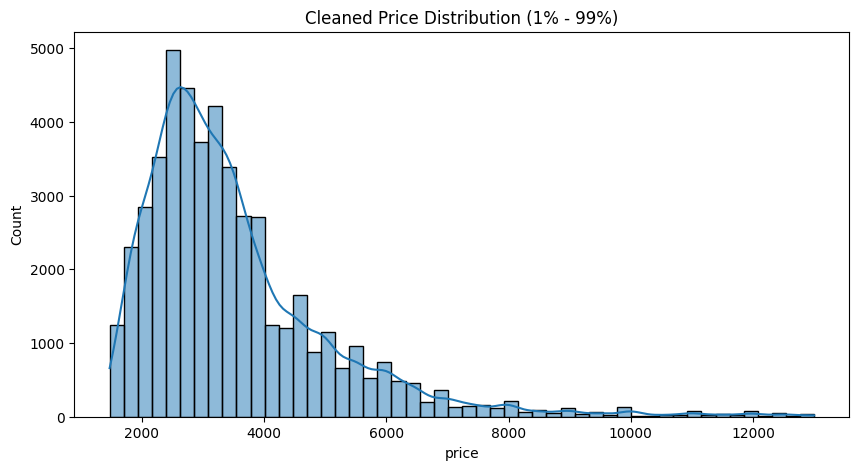

In [3]:
# The task asks to drop 1st and 99th percentiles
lower_limit = np.percentile(df['price'], 1)
upper_limit = np.percentile(df['price'], 99)

df_filtered = df[(df['price'] >= lower_limit) & (df['price'] <= upper_limit)].copy()

# Visualize the new distribution
plt.figure(figsize=(10, 5))
sns.histplot(df_filtered['price'], bins=50, kde=True)
plt.title('Cleaned Price Distribution (1% - 99%)')
plt.show()

interest_level
low       33697
medium    11116
high       3566
Name: count, dtype: int64


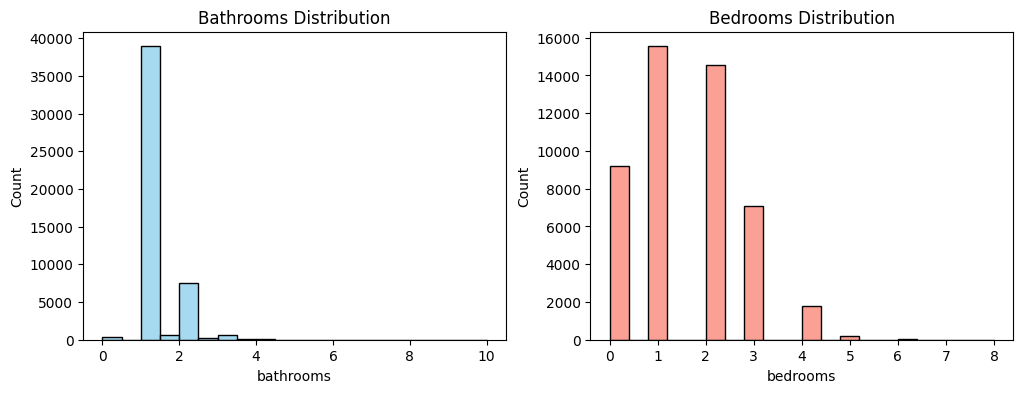

In [4]:
# Check types and value counts
print(df_filtered['interest_level'].value_counts())

# Encode interest_level: low=0, medium=1, high=2
mapping = {'low': 0, 'medium': 1, 'high': 2}
df_filtered['interest_level'] = df_filtered['interest_level'].map(mapping)

# Plot histograms for bathrooms and bedrooms
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_filtered['bathrooms'], bins=20, ax=axes[0], color='skyblue').set_title('Bathrooms Distribution')
sns.histplot(df_filtered['bedrooms'], bins=20, ax=axes[1], color='salmon').set_title('Bedrooms Distribution')
plt.show()

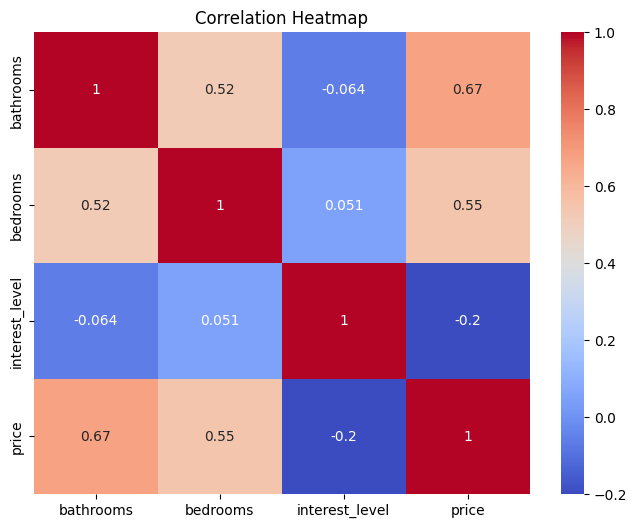

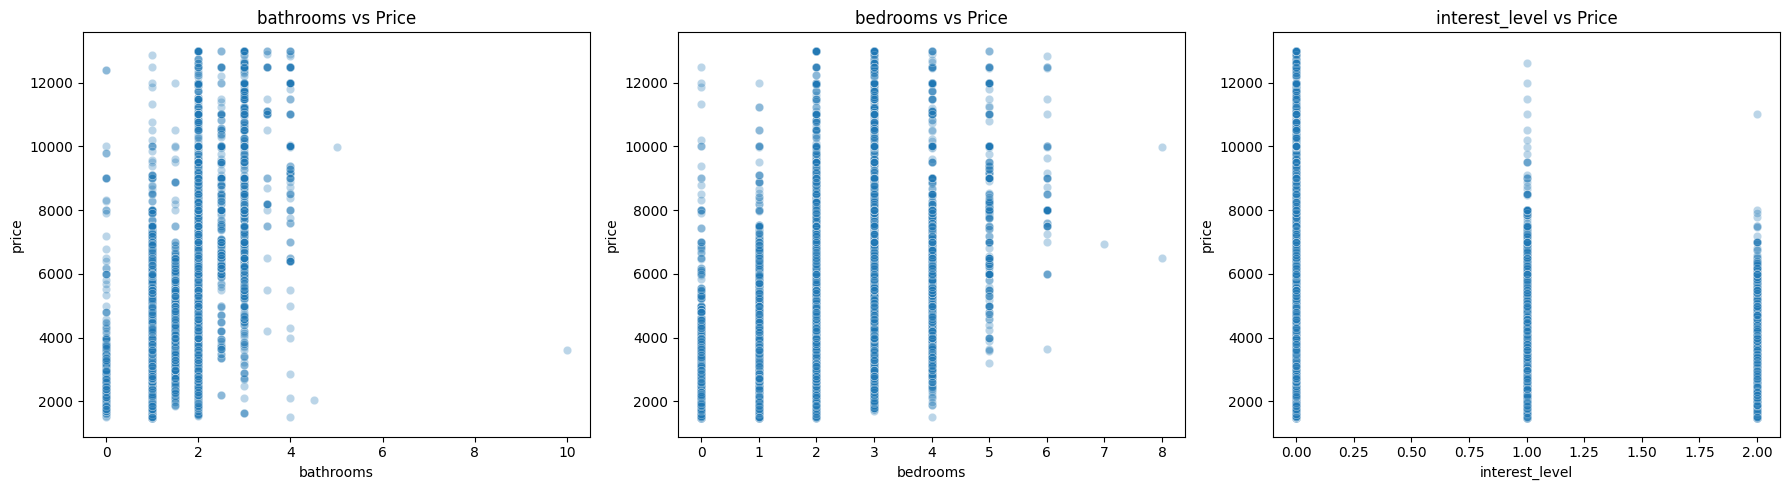

In [5]:
# 1. Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df_filtered[['bathrooms', 'bedrooms', 'interest_level', 'price']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

# 2. Scatterplots (3 plots: features vs price)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
features = ['bathrooms', 'bedrooms', 'interest_level']

for i, col in enumerate(features):
    sns.scatterplot(data=df_filtered, x=col, y='price', alpha=0.3, ax=axes[i])
    axes[i].set_title(f'{col} vs Price')

plt.tight_layout()
plt.show()

In [6]:
# Creating squared features (as requested in instructions)
df_filtered['bathrooms_squared'] = df_filtered['bathrooms'] ** 2
df_filtered['bedrooms_squared'] = df_filtered['bedrooms'] ** 2
df_filtered['interest_level_squared'] = df_filtered['interest_level'] ** 2

# For training, we use ONLY bathrooms and bedrooms as per instructions
from sklearn.model_selection import train_test_split

X = df_filtered[['bathrooms', 'bedrooms']]
y = df_filtered['price']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Apply PolynomialFeatures degree 10
poly = PolynomialFeatures(degree=10)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [7]:
# Create empty results tables
result_MAE = pd.DataFrame(columns=['model', 'train', 'test'])
result_RMSE = pd.DataFrame(columns=['model', 'train', 'test'])

def log_results(name, train_pred, test_pred):
    # Calculate MAE
    mae_train = mean_absolute_error(y_train, train_pred)
    mae_test = mean_absolute_error(y_test, test_pred)
    # Calculate RMSE
    rmse_train = np.sqrt(mean_squared_error(y_train, train_pred))
    rmse_test = np.sqrt(mean_squared_error(y_test, test_pred))
    
    # Append to tables
    result_MAE.loc[len(result_MAE)] = [name, mae_train, mae_test]
    result_RMSE.loc[len(result_RMSE)] = [name, rmse_train, rmse_test]

# 1. Linear Regression
lr = LinearRegression().fit(X_train_poly, y_train)
log_results('linear_regression', lr.predict(X_train_poly), lr.predict(X_test_poly))

# 2. Decision Tree
dt = DecisionTreeRegressor(random_state=21).fit(X_train, y_train)
log_results('decision_tree', dt.predict(X_train), dt.predict(X_test))

# 3. Naive Models (Mean and Median)
mean_guess = y_train.mean()
median_guess = y_train.median()

log_results('naive_mean', [mean_guess]*len(y_train), [mean_guess]*len(y_test))
log_results('naive_median', [median_guess]*len(y_train), [median_guess]*len(y_test))

# Final Output
print("--- Result MAE ---")
print(result_MAE)
print("\n--- Result RMSE ---")
print(result_RMSE)

--- Result MAE ---
               model        train         test
0  linear_regression   755.345491   760.735792
1      decision_tree   755.352697   759.526414
2         naive_mean  1137.760556  1143.077343
3       naive_median  1084.589257  1092.695329

--- Result RMSE ---
               model        train         test
0  linear_regression  1075.252157  1100.028648
1      decision_tree  1075.206434  1089.231913
2         naive_mean  1599.229452  1591.302875
3       naive_median  1645.449541  1639.375180
